# External data EDA: R-Judge, ATBench, AgentRisk

What the monitor learns from in Phase A, and what it is tested on: SAFE / UNSAFE balance, risk types,
risk causes, lengths and known shortcuts, for all three external sources.

**Phase A training pool (as planned today):**
- R-Judge: the 300-record train sample (`r_judge_train_sample300.txt`, 150 SAFE + 150 UNSAFE, R12.2)
- ATBench: the 300-record train sample (`atbench_train_sample300.txt`, R12.2)
- AgentRisk: all of its train split (394; no sample size decided yet, R12.5)

Val and test are the full val / test splits of each source.

Notes:
- R-Judge risk types are taken from the finished blind re-check **in memory** (`map_risk.load_human_types`),
  because `r_judge.jsonl` still holds older types for 68 records until `map_risk` is rerun. No file is changed.
- AgentRisk items have no licence: this notebook shows **counts only**, never item text.
- Run from the repo root or from `notebooks/`. Needs `pandas`, `matplotlib`.

## Summary of findings

(Data as of 2026-10-26.)

1. **2,147 external records**: R-Judge 531, ATBench 999, AgentRisk 617. Every split of every source is close to 50/50 (45–53% UNSAFE).
2. **Phase A training pool = 994 records** (R-Judge 300 + ATBench 300 + AgentRisk 394): 513 SAFE / 481 UNSAFE (48% UNSAFE). Val 245, test 440.
3. **Risk types are unbalanced.** Of the 481 UNSAFE training records: PRIVACY_LEAKAGE 254 (53%), SECURITY 64 (13%), FINANCIAL_LOSS 55 (11%), OTHER 49 (10%), ACCESS_CONTROL 42 (9%), DATA_LOSS 17 (4%).
   - The ATBench sample's UNSAFE half was re-picked by our risk type on 2026-10-26 (about 30 per type). Before: PRIVACY_LEAKAGE 274 (57%), FINANCIAL_LOSS 37, ACCESS_CONTROL 26.
   - AgentRisk is 68% PRIVACY_LEAKAGE and has no ACCESS_CONTROL.
   - ATBench has no DATA_LOSS at all (its map sends nothing there).
4. **What is left to balance with:** the unused ATBench train records are now mostly SECURITY (101) and PRIVACY_LEAKAGE (62), with no FINANCIAL_LOSS and 2 ACCESS_CONTROL left. A smaller AgentRisk sample would cut privacy further; more DATA_LOSS can only come from our own records.
5. **Small test cells:** only 4 UNSAFE DATA_LOSS records and 13 ACCESS_CONTROL in test, so those per-type F1 scores will be noisy.
6. **Shortcuts** (keep the records, report with and without):
   - AgentRisk: 250 of 329 SAFE records (76%) are replies to the user; no reply is UNSAFE. Without them AgentRisk is 288 UNSAFE / 79 SAFE.
   - ATBench length: 51 of the 56 records over 4,096 tokens are UNSAFE, and all 36 over 8,192.
   - ATBench tool errors: the word "error" appears in tool output of 22% of UNSAFE vs 12% of SAFE records.
   - R-Judge: UNSAFE records are somewhat longer (median 514 vs 384 tokens).
7. **Risk cause (AgentRisk only):** 69% UNTRUSTED_CONTENT; 158 of the 195 privacy items are untrusted-content (prompt injection), so type and cause are closely tied.
8. R-Judge's Finance category leans SAFE (87 SAFE vs 38 UNSAFE).


## 0. Load

In [1]:
import json, re, sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data" / "external").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.external.map_risk import load_human_types

EXT = ROOT / "data" / "external"
SPLITS = EXT / "splits"
SOURCES = {"r_judge": "R-Judge", "atbench": "ATBench", "agentrisk": "AgentRisk"}
TYPES = ["PRIVACY_LEAKAGE", "SECURITY", "FINANCIAL_LOSS", "DATA_LOSS", "ACCESS_CONTROL", "OTHER"]
SPLIT_ORDER = ["train", "val", "test"]

def ids(name):
    p = SPLITS / f"{name}.txt"
    return set(p.read_text(encoding="utf-8").split()) if p.exists() else set()

human = load_human_types()
rows = []
for src, label in SOURCES.items():
    path = EXT / f"{src}.jsonl"
    if not path.exists():
        print(f"{path} missing (AgentRisk: run `python -m src.external.agentrisk`)")
        continue
    sample = ids(f"{src}_train_sample300")
    for line in path.open(encoding="utf-8"):
        r = json.loads(line)
        g, traj = r["gold"], r["visible"]["trajectory"]
        rtype = g["risk_type"]
        if src == "r_judge" and g["risk_label"] == "UNSAFE":
            rtype = human.get(r["record_id"])          # finished re-check, applied in memory
        tool_text = " ".join(m["text"] or "" for m in traj if m["role"] == "tool")
        rows.append({
            "source": label, "record_id": r["record_id"], "split": r["split"], "label": g["risk_label"],
            "risk_type": rtype, "risk_cause": g["risk_cause"],
            "phase_a_train": (r["split"] == "train") and (src == "agentrisk" or r["record_id"] in sample),
            "tokens": r["meta"]["n_tokens"], "turns": len(traj), "tool_turns": sum(m["role"] == "tool" for m in traj),
            "tool_error": bool(re.search(r"error", tool_text, re.I)),
            "flags": tuple(r["meta"].get("flags") or ()),
            "category": r["meta"].get("category"),
        })
df = pd.DataFrame(rows)
df["pool"] = df["split"].where(df["split"] != "train", df["phase_a_train"].map({True: "train (Phase A)", False: "train (not used)"}))
print(len(df), "records"); df.groupby("source").size()

2147 records


source
ATBench      999
AgentRisk    617
R-Judge      531
dtype: int64

In [2]:
# Colours: fixed categorical order (blue, orange, aqua); text stays in neutral ink
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a"}
LABEL_C = {"SAFE": C["blue"], "UNSAFE": C["orange"]}
SRC_C = {"R-Judge": C["blue"], "ATBench": C["orange"], "AgentRisk": C["aqua"]}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "text.color": "#0b0b0b", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10})

def pct_table(t):
    return (t.div(t.sum(axis=1), axis=0) * 100).round(1)

## 1. Size and SAFE / UNSAFE by source and split

In [3]:
t = df.pivot_table(index=["source", "split"], columns="label", values="record_id", aggfunc="count", fill_value=0)
t = t.reindex([(s, sp) for s in SOURCES.values() for sp in SPLIT_ORDER])
t["total"] = t.sum(axis=1); t["% UNSAFE"] = (100 * t["UNSAFE"] / t["total"]).round(1)
t

label            SAFE  UNSAFE  total  % UNSAFE
source    split                               
R-Judge   train   179     190    369      51.5
          val      26      21     47      44.7
          test     60      55    115      47.8
ATBench   train   358     341    699      48.8
          val      47      53    100      53.0
          test     98     102    200      51.0
AgentRisk train   213     181    394      45.9
          val      50      48     98      49.0
          test     66      59    125      47.2

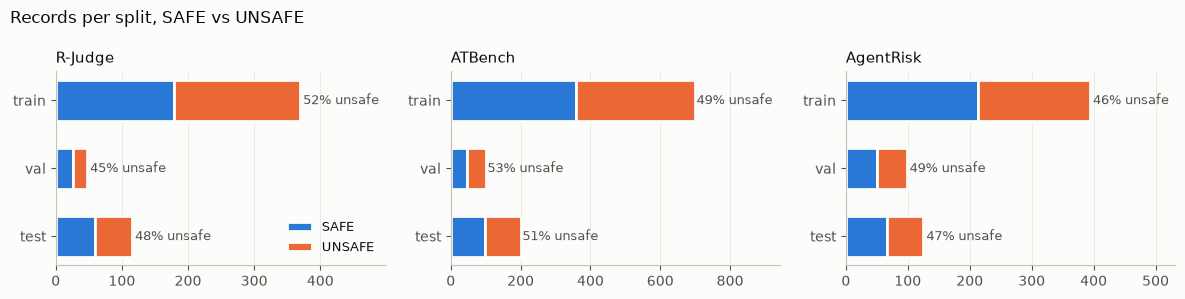

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=False)
for ax, src in zip(axes, SOURCES.values()):
    part = t.loc[src]
    left = 0
    for lab in ("SAFE", "UNSAFE"):
        ax.barh(SPLIT_ORDER[::-1], part.loc[SPLIT_ORDER[::-1], lab], left=left, color=LABEL_C[lab],
                edgecolor="#fcfcfb", linewidth=2, height=0.6, label=lab)
        left = left + part.loc[SPLIT_ORDER[::-1], lab].values
    for y, sp in enumerate(SPLIT_ORDER[::-1]):
        ax.text(part.loc[sp, "total"] + 5, y, f"{part.loc[sp, '% UNSAFE']:.0f}% unsafe", va="center", fontsize=9, color="#52514e")
    ax.set_title(src, loc="left", fontsize=11); ax.set_xlim(0, part["total"].max() * 1.35); ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
fig.suptitle("Records per split, SAFE vs UNSAFE", x=0.01, ha="left", fontsize=12); fig.tight_layout(); plt.show()

## 2. Phase A training pool vs val / test

In [5]:
pool_order = ["train (Phase A)", "train (not used)", "val", "test"]
p = df.pivot_table(index="pool", columns="source", values="record_id", aggfunc="count", fill_value=0)
p = p.reindex(pool_order)[list(SOURCES.values())]; p["all"] = p.sum(axis=1)
p

source,R-Judge,ATBench,AgentRisk,all
pool,,,,
train (Phase A),300,300,394,994
train (not used),69,399,0,468
val,47,100,98,245
test,115,200,125,440


In [6]:
pa = df[df["pool"] == "train (Phase A)"]
lab = pa.pivot_table(index="source", columns="label", values="record_id", aggfunc="count", fill_value=0).reindex(SOURCES.values())
lab.loc["Phase A total"] = lab.sum(); lab["% UNSAFE"] = (100 * lab["UNSAFE"] / lab.sum(axis=1)).round(1)
lab

label,SAFE,UNSAFE,% UNSAFE
source,,,
R-Judge,150,150,50.0
ATBench,150,150,50.0
AgentRisk,213,181,45.9
Phase A total,513,481,48.4


## 3. Risk types (UNSAFE records)

Counts per source and split; `None` = UNSAFE record without a type yet.

In [7]:
u = df[df["label"] == "UNSAFE"].copy(); u["risk_type"] = u["risk_type"].fillna("None")
rt = u.pivot_table(index=["source", "split"], columns="risk_type", values="record_id", aggfunc="count", fill_value=0)
rt = rt.reindex([(s, sp) for s in SOURCES.values() for sp in SPLIT_ORDER]).fillna(0).astype(int)
rt = rt[[c for c in TYPES + ["None"] if c in rt.columns]]
rt

risk_type        PRIVACY_LEAKAGE  SECURITY  FINANCIAL_LOSS  DATA_LOSS  \
source    split                                                         
R-Judge   train               99        12              10          9   
          val                  6         7               0          1   
          test                28         9               4          4   
ATBench   train               93       131              27          0   
          val                 12        24               6          0   
          test                21        36              12          0   
AgentRisk train              124        22              18          8   
          val                 33         8               4          2   
          test                38         9               6          0   

risk_type        ACCESS_CONTROL  OTHER  None  
source    split                               
R-Judge   train              11      9    40  
          val                 6      1     0  
          test                3      7     0  
ATBench   train              33     57     0  
          val                 5      6     0  
          test               10     23     0  
AgentRisk train               0      9     0  
          val                 0      1     0  
          test                0      6     0

In [8]:
print("Share of each type among UNSAFE records (%), whole source:")
pct_table(u.pivot_table(index="source", columns="risk_type", values="record_id", aggfunc="count", fill_value=0)
          .reindex(SOURCES.values())[[c for c in TYPES if c in u["risk_type"].unique()]])

Share of each type among UNSAFE records (%), whole source:


risk_type,PRIVACY_LEAKAGE,SECURITY,FINANCIAL_LOSS,DATA_LOSS,ACCESS_CONTROL,OTHER
source,,,,,,
R-Judge,58.8,12.4,6.2,6.2,8.8,7.5
ATBench,25.4,38.5,9.1,0.0,9.7,17.3
AgentRisk,67.7,13.5,9.7,3.5,0.0,5.6


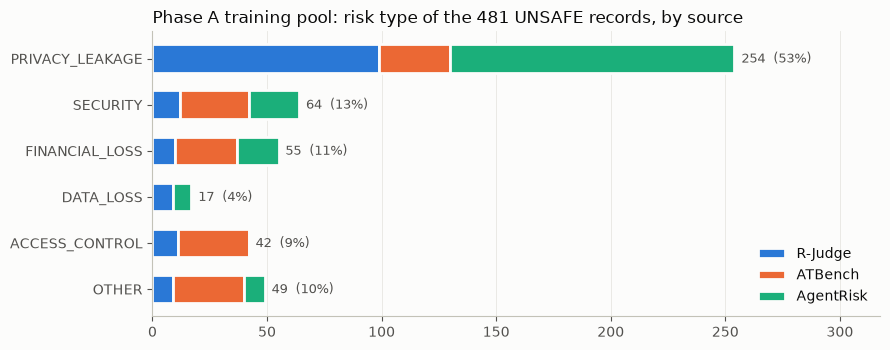

source,R-Judge,ATBench,AgentRisk,total,pct
risk_type,,,,,
PRIVACY_LEAKAGE,99,31,124,254,52.8
SECURITY,12,30,22,64,13.3
FINANCIAL_LOSS,10,27,18,55,11.4
DATA_LOSS,9,0,8,17,3.5
ACCESS_CONTROL,11,31,0,42,8.7
OTHER,9,31,9,49,10.2


In [9]:
pau = u[u["pool"] == "train (Phase A)"]
tab = pau.pivot_table(index="risk_type", columns="source", values="record_id", aggfunc="count", fill_value=0)
tab = tab.reindex([c for c in TYPES if c in tab.index])[[s for s in SOURCES.values() if s in tab.columns]]
fig, ax = plt.subplots(figsize=(9, 3.6))
left = pd.Series(0, index=tab.index)
for src in tab.columns:
    ax.barh(tab.index[::-1], tab[src][::-1], left=left[::-1], color=SRC_C[src], edgecolor="#fcfcfb", linewidth=2, height=0.62, label=src)
    left += tab[src]
for y, (name, n) in enumerate(left[::-1].items()):
    ax.text(n + 3, y, f"{n}  ({100 * n / left.sum():.0f}%)", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, left.max() * 1.25); ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Phase A training pool: risk type of the {int(left.sum())} UNSAFE records, by source", loc="left", fontsize=12)
fig.tight_layout(); plt.show()
tab.assign(total=tab.sum(axis=1), pct=(100 * tab.sum(axis=1) / tab.values.sum()).round(1))

In [10]:
print("UNSAFE risk types in each pool, all sources together:")
pool_rt = u.pivot_table(index="pool", columns="risk_type", values="record_id", aggfunc="count", fill_value=0).reindex(pool_order)
pool_rt[[c for c in TYPES + ["None"] if c in pool_rt.columns]]

UNSAFE risk types in each pool, all sources together:


risk_type,PRIVACY_LEAKAGE,SECURITY,FINANCIAL_LOSS,DATA_LOSS,ACCESS_CONTROL,OTHER,None
pool,,,,,,,
train (Phase A),254,64,55,17,42,49,0
train (not used),62,101,0,0,2,26,40
val,51,39,10,3,11,8,0
test,87,54,22,4,13,36,0


## 4. Risk cause (AgentRisk only)

R-Judge and ATBench have no risk cause (R3.4).

In [11]:
ar = df[(df["source"] == "AgentRisk") & (df["label"] == "UNSAFE")]
rc = ar.pivot_table(index="split", columns="risk_cause", values="record_id", aggfunc="count", fill_value=0).reindex(SPLIT_ORDER)
rc["total"] = rc.sum(axis=1); rc

risk_cause,AGENT_ERROR,ENVIRONMENT_STATE,UNTRUSTED_CONTENT,USER_REQUEST,total
split,,,,,
train,23,23,123,12,181
val,10,3,35,0,48
test,11,4,41,3,59


In [12]:
pd.crosstab(ar["risk_type"], ar["risk_cause"], margins=True)

risk_cause,AGENT_ERROR,ENVIRONMENT_STATE,UNTRUSTED_CONTENT,USER_REQUEST,All
risk_type,,,,,
DATA_LOSS,6,1,3,0,10
FINANCIAL_LOSS,5,7,14,2,28
OTHER,2,3,5,6,16
PRIVACY_LEAKAGE,18,14,158,5,195
SECURITY,13,5,19,2,39
All,44,30,199,15,288


## 5. Length (Qwen3 tokens of the visible part)

In [13]:
desc = df.groupby(["source", "label"])["tokens"].describe(percentiles=[0.5, 0.95])[["count", "mean", "50%", "95%", "max"]].round(0)
desc["over 4,096"] = df.groupby(["source", "label"])["tokens"].apply(lambda s: int((s > 4096).sum()))
desc["over 8,192"] = df.groupby(["source", "label"])["tokens"].apply(lambda s: int((s > 8192).sum()))
desc

count    mean     50%      95%       max  over 4,096  \
source    label                                                          
ATBench   SAFE    503.0  1395.0  1274.0   2875.0    5326.0           5   
          UNSAFE  496.0  5502.0  1331.0  21427.0  100824.0          51   
AgentRisk SAFE    329.0   991.0   930.0   1785.0    3164.0           0   
          UNSAFE  288.0  1016.0   914.0   1912.0    2592.0           0   
R-Judge   SAFE    265.0   386.0   384.0    584.0    1394.0           0   
          UNSAFE  266.0   497.0   514.0    945.0    1444.0           0   

                  over 8,192  
source    label               
ATBench   SAFE             0  
          UNSAFE          36  
AgentRisk SAFE             0  
          UNSAFE           0  
R-Judge   SAFE             0  
          UNSAFE           0

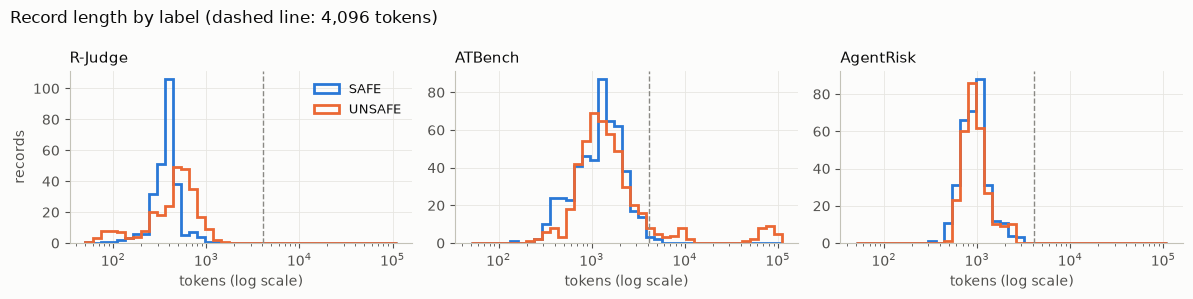

In [14]:
import numpy as np
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
bins = np.logspace(np.log10(50), np.log10(df["tokens"].max() * 1.1), 40)
for ax, src in zip(axes, SOURCES.values()):
    part = df[df["source"] == src]
    for lab in ("SAFE", "UNSAFE"):
        ax.hist(part.loc[part["label"] == lab, "tokens"], bins=bins, histtype="step", linewidth=2, color=LABEL_C[lab], label=lab)
    ax.set_xscale("log"); ax.set_title(src, loc="left", fontsize=11); ax.set_xlabel("tokens (log scale)")
    ax.axvline(4096, color="#8a8984", linewidth=1, linestyle="--")
axes[0].set_ylabel("records"); axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Record length by label (dashed line: 4,096 tokens)", x=0.01, ha="left", fontsize=12); fig.tight_layout(); plt.show()

## 6. Conversation shape

In [15]:
df.groupby(["source", "label"])[["turns", "tool_turns"]].agg(["median", "mean", "max"]).round(1)

turns           tool_turns         
                 median  mean max     median mean max
source    label                                      
ATBench   SAFE     11.0   9.2  19        3.0  2.6   4
          UNSAFE    9.0  10.8  63        3.0  3.4  22
AgentRisk SAFE      8.0   9.3  14        3.0  3.7   6
          UNSAFE   10.0   9.8  14        4.0  3.9   6
R-Judge   SAFE      5.0   5.5  25        1.0  1.2   9
          UNSAFE    7.0   6.7  23        2.0  1.8   8

## 7. Known shortcuts

A shortcut is a surface feature that predicts the label without judging the risk. We keep these records and report results with and without them.

In [16]:
print("Share of records whose tool output contains the word 'error' (%):")
(df.pivot_table(index="source", columns="label", values="tool_error", aggfunc="mean") * 100).round(1).reindex(SOURCES.values())

Share of records whose tool output contains the word 'error' (%):


label,SAFE,UNSAFE
source,,
R-Judge,0.0,0.8
ATBench,11.5,22.2
AgentRisk,3.3,2.1


In [17]:
ar_all = df[df["source"] == "AgentRisk"]
flag_rows = []
for f in ("reply_to_user", "rjudge_prompt_overlap"):
    has = ar_all["flags"].apply(lambda fl: f in fl)
    for sp in SPLIT_ORDER:
        part = ar_all[has & (ar_all["split"] == sp)]
        flag_rows.append({"flag": f, "split": sp, "records": len(part), "SAFE": int((part["label"] == "SAFE").sum()),
                          "UNSAFE": int((part["label"] == "UNSAFE").sum())})
pd.DataFrame(flag_rows).set_index(["flag", "split"])

records  SAFE  UNSAFE
flag                  split                       
reply_to_user         train      159   159       0
                      val         43    43       0
                      test        48    48       0
rjudge_prompt_overlap train       22    19       3
                      val         27    15      12
                      test        11     8       3

In [18]:
rep = ar_all[ar_all["flags"].apply(lambda fl: "reply_to_user" in fl)]
safe = ar_all[ar_all["label"] == "SAFE"]
print(f"AgentRisk: {len(rep)} of {len(safe)} SAFE records ({100 * len(rep) / len(safe):.0f}%) are replies to the user; "
      f"{int((rep['label'] == 'UNSAFE').sum())} replies are UNSAFE.")
print("Without replies, AgentRisk is", dict(ar_all[~ar_all.index.isin(rep.index)]["label"].value_counts()))

AgentRisk: 250 of 329 SAFE records (76%) are replies to the user; 0 replies are UNSAFE.
Without replies, AgentRisk is {'UNSAFE': np.int64(288), 'SAFE': np.int64(79)}


## 8. Source categories

In [19]:
rj = df[df["source"] == "R-Judge"]
pd.crosstab(rj["category"], rj["label"], margins=True)

label,SAFE,UNSAFE,All
category,,,
Application,97,140,237
Finance,87,38,125
IoT,6,7,13
Program,60,63,123
Web,15,18,33
All,265,266,531
